In [3]:
# %load_ext autoreload
%reload_ext autoreload
%autoreload 2

In [4]:
#!/usr/bin/env python3

import gtsam
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
%matplotlib widget
import numpy as np
np.set_printoptions(linewidth=np.inf, suppress=True)
import copy
import time
from pathlib import Path
import open3d as o3d
from scipy.spatial import KDTree

# Local imports
import FGVizHelpers as fgtools
from SessionManager import SessionManager
from SessionUpdater import SessionUpdater

from src.multiSession.sparcification.NFR import GraphSparsification



Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


## Load and plot original graph

495


Text(0.5, 1.0, 'Aligned Via GPS Only')

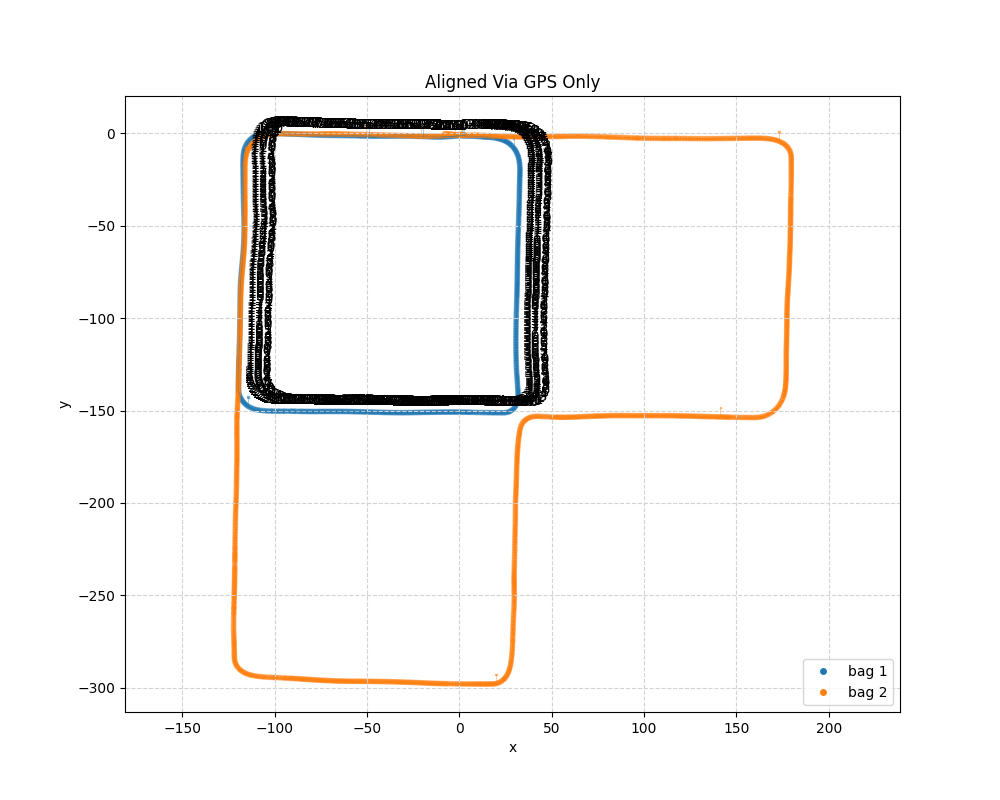

In [3]:
# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------
directory1 = Path("../results/urban/around_block_initial/")
directory2 = Path("../results/urban/around_block_short_reconnect/")
directory3 = Path("../results/urban/quick_map_disconnect/")
fileName = "fullSavedGraph.g2o"

session1 = SessionManager(directory1 / fileName)
session2 = SessionManager(directory2 / fileName)
# session3 = SessionManager(directory3 / fileName)

session1.Optimize()
session2.Optimize()
# session3.Optimize()

session1.LoadScans(directory1 / "Scans")
session2.LoadScans(directory2 / "Scans")
# session3.LoadScans(directory3 / "Scans")

bag_colors = ['tab:blue', 'tab:orange', 'tab:green']

print(session1.graph.size())

ax = fgtools.plot_graph(session1.graph, session1.values, color_override=bag_colors[0], alpha=0.5, addKeyLabels=True)
# fgtools.plot_graph_covariances(session1.values.keys(), session1.graph, session1.values, ax=ax)

fgtools.plot_graph(session2.graph, session2.orig_values_, ax=ax, color_override=bag_colors[1], alpha=0.5)
# fgtools.plot_graph_covariances(session2.values.keys(), session2.graph, session2.values, ax=ax)

# fgtools.plot_graph(session3.graph, session3.values, ax=ax, color_override=bag_colors[2], alpha=0.5)
# fgtools.plot_graph_covariances(session3.values.keys(), session3.graph, session3.values, ax=ax)

legendElements = [
                    Line2D([0],[0], marker='o', color='w', label="bag 1", markerfacecolor=bag_colors[0]),
                    Line2D([0],[0], marker='o', color='w', label="bag 2", markerfacecolor=bag_colors[1]),
                    # Line2D([0],[0], marker='o', color='w', label="bag 3", markerfacecolor=bag_colors[2]),
                ]
ax.legend(handles=legendElements, loc='lower right')
ax.set_title("Aligned Via GPS Only")

# globalMap1 = session1.CreateGlobalPCD((1, 0, 0))
# globalMap2 = session2.CreateGlobalPCD((0, 1, 0))
# globalMap3 = session3.CreateGlobalPCD((0, 0, 1))

# o3d.visualization.draw_geometries([globalMap1, globalMap2, globalMap3])


In [4]:
session1.graph.size()

495

In [17]:
test1 = SessionManager(directory1 / fileName, True)
test2 = SessionManager(directory3 / fileName, True)
test1.UpdateISAM2()
test2.UpdateISAM2()

test1.LoadScans(directory1 / "Scans")
test2.LoadScans(directory3 / "Scans")

pc1 = test1.CreateGlobalPCD((1., 0., 0.))
pc2 = test2.CreateGlobalPCD((0., 1., 0.))

o3d.visualization.draw_geometries([pc1, pc2])

In [10]:
import gtsam

print(gtsam.__file__)
print(gtsam.ISAM2)
print(hasattr(gtsam.ISAM2, "marginalizeLeaves"))
print(dir(gtsam.ISAM2))

/home/benb/miniforge3/envs/blocklio/lib/python3.12/site-packages/gtsam/__init__.py
<class 'gtsam.gtsam.ISAM2'>
True
['__class__', '__delattr__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', 'calculateBestEstimate', 'calculateEstimate', 'calculateEstimateCal3Bundler', 'calculateEstimateCal3DS2', 'calculateEstimateCal3_S2', 'calculateEstimateCal3f', 'calculateEstimateEssentialMatrix', 'calculateEstimateFundamentalMatrix', 'calculateEstimateMatrix', 'calculateEstimatePinholeCameraCal3Bundler', 'calculateEstimatePinholeCameraCal3Fisheye', 'calculateEstimatePinholeCameraCal3Unified', 'calculateEstimatePinholeCameraCal3_S2', 'calculateEstimatePoint2', 'calculateEstimatePoint3', 'calculateEstimatePose2', 'calculateEstimatePose3', 'calcul

In [11]:
import numpy as np
import gtsam
from gtsam import (
    NonlinearFactorGraph,
    Values,
    PriorFactorDouble,
    BetweenFactorDouble,
    noiseModel,
    FixedLagSmoother
)
from gtsam_unstable import IncrementalFixedLagSmoother
from gtsam.symbol_shorthand import X



# ---------------------------------------------------------
# Fixed lag size (seconds)
# Variables older than current_time - lag are marginalized
# ---------------------------------------------------------
lag = 5.0

smoother = IncrementalFixedLagSmoother(lag)

# Noise models
prior_noise = noiseModel.Isotropic.Sigma(1, 0.1)
odom_noise = noiseModel.Isotropic.Sigma(1, 0.2)
meas_noise = noiseModel.Isotropic.Sigma(1, 0.5)

dt = 1.0
velocity = 1.0

current_time = 0.0

for k in range(15):

    graph = NonlinearFactorGraph()
    values = Values()
    timestamps = {}

    key = X(k)

    # -----------------------------------------------------
    # Simulated ground truth
    # x_k = v * t
    # -----------------------------------------------------
    true_position = velocity * current_time

    # noisy measurement
    measured_position = (
        true_position + np.random.randn() * 0.5
    )

    # -----------------------------------------------------
    # Initialize estimate
    # -----------------------------------------------------
    initial_guess = measured_position
    values.insert(key, initial_guess)

    timestamps[key] = current_time

    # -----------------------------------------------------
    # Prior on first state
    # -----------------------------------------------------
    if k == 0:

        graph.add(
            PriorFactorDouble(
                key,
                0.0,
                prior_noise,
            )
        )

    else:

        prev_key = X(k - 1)

        # Constant velocity model:
        # x_k - x_{k-1} = v * dt
        graph.add(
            BetweenFactorDouble(
                prev_key,
                key,
                velocity * dt,
                odom_noise,
            )
        )

    # -----------------------------------------------------
    # Add measurement factor
    # This acts like a GPS measurement
    # -----------------------------------------------------
    graph.add(
        PriorFactorDouble(
            key,
            measured_position,
            meas_noise,
        )
    )

    # -----------------------------------------------------
    # Update smoother
    # -----------------------------------------------------
    smoother.update(
        graph,
        values,
        timestamps,
    )

    # -----------------------------------------------------
    # Get current estimate
    # -----------------------------------------------------
    result = smoother.calculateEstimate()

    print(f"\nTime step {k}")

    for j in range(max(0, k - 6), k + 1):

        test_key = X(j)

        if result.exists(test_key):

            estimate = result.atDouble(test_key)

            print(
                f"  x[{j}] = {estimate:.3f}"
            )

    current_time += dt





Time step 0
  x[0] = -0.024

Time step 1
  x[0] = -0.042
  x[1] = 0.887

Time step 2
  x[0] = -0.021
  x[1] = 0.994
  x[2] = 2.096

Time step 3
  x[0] = -0.022
  x[1] = 0.988
  x[2] = 2.086
  x[3] = 3.079

Time step 4
  x[0] = -0.014
  x[1] = 1.028
  x[2] = 2.165
  x[3] = 3.209
  x[4] = 4.281

Time step 5
  x[0] = -0.015
  x[1] = 1.022
  x[2] = 2.153
  x[3] = 3.190
  x[4] = 4.251
  x[5] = 5.235

Time step 6
  x[1] = 1.026
  x[2] = 2.161
  x[3] = 3.203
  x[4] = 4.271
  x[5] = 5.265
  x[6] = 6.281

Time step 7
  x[2] = 2.158
  x[3] = 3.198
  x[4] = 4.264
  x[5] = 5.255
  x[6] = 6.265
  x[7] = 7.257

Time step 8
  x[3] = 3.158
  x[4] = 4.202
  x[5] = 5.160
  x[6] = 6.123
  x[7] = 7.045
  x[8] = 7.941

Time step 9
  x[4] = 4.137
  x[5] = 5.062
  x[6] = 5.976
  x[7] = 6.826
  x[8] = 7.614
  x[9] = 8.454

Time step 10
  x[5] = 5.032
  x[6] = 5.930
  x[7] = 6.757
  x[8] = 7.512
  x[9] = 8.302
  x[10] = 9.228

Time step 11
  x[6] = 5.957
  x[7] = 6.797
  x[8] = 7.572
  x[9] = 8.391
  x[10] = 

In [4]:
graph = session2.graph
values = session2.values

subGraph, subValues = fgtools.createSubGraph(graph, values, [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
# fgtools.plot_graph(subGraph, subValues)

In [5]:
# graph.print()
for i in range(subGraph.size()):
    if i > 5:
        break
    # print(i)
    f = graph.at(i)
    # f.print()

gs = GraphSparsification(subGraph, subValues, showPlots=False)

gs.MarginalizeNodes([0])

new_graph = gs.graph
new_values = gs.values





Initial Optimization
Optimizing using LevenbergMarquardt...
Optimization time: 0.001397848129272461



In [ ]:

def rekey_linear_container_factor_unary(f, new_keys):

    hf = f.factor()  # HessianFactor

    info = hf.augmentedInformation()

    #
    # Split augmented info matrix
    #
    G = info[:-1, :-1]
    g = info[:-1, -1]
    c = info[-1, -1]

    #
    # Rebuild HessianFactor with new key
    #
    new_hf = gtsam.HessianFactor(
        new_keys,
        G,
        g,
        c
    )

    #
    # Rebuild LinearContainerFactor with new HessianFactor
    #
    return gtsam.LinearContainerFactor(new_hf)

keyMapping = {}
for i in range(new_graph.size()):
    f = new_graph.at(i)
    for k in f.keys():
        keyMapping[k] = gtsam.Symbol('a', k).key()

new_graph2 = gtsam.NonlinearFactorGraph()
for i in range(new_graph.size()):
    f = new_graph.at(i)
    if isinstance(f, gtsam.LinearContainerFactor):
        new_keys = [keyMapping[k] for k in f.keys()]
        f.print()
        if len(new_keys) == 1:
            lcf = rekey_linear_container_factor_unary(f, new_keys[0])
            lcf.print()
        else:
            print(f"Error: More than one key in LinearContainerFactor")


LinearContainerFactor  keys = { 1 }


   Stored Factor
 keys: 1(6) 
Augmented information matrix: [
	99.99, -4.07169e-10, -1.21926e-10, -1.44329e-15, -1.06465e-10, 3.55726e-10, 3.22226e-09;
	-4.07169e-10, 99.99, -3.46745e-12, 1.06414e-10, -1.42109e-14, -1.15051e-08, -1.04791e-07;
	-1.21926e-10, -3.46745e-12, 99.99, -3.55627e-10, 1.15022e-08, 0, 2.31161e-09;
	-1.44329e-15, 1.06414e-10, -3.55627e-10, 1.00026e-08, 6.16035e-14, -7.10543e-15, -2.39075e-08;
	-1.06465e-10, -1.42109e-14, 1.15022e-08, 6.16035e-14, 1.00026e-08, 0, 3.28173e-09;
	3.55726e-10, -1.15051e-08, 0, -7.10543e-15, 0, 1.00026e-08, 1.82095e-07;
	3.22226e-09, -1.04791e-07, 2.31161e-09, -2.39075e-08, 3.28173e-09, 1.82095e-07, 3.3741e-06
]
LinearContainerFactor  keys = { a1 }
   Stored Factor
 keys: a1(6) 
Augmented information matrix: [
	99.99, -4.07169e-10, -1.21926e-10, -1.44329e-15, -1.06465e-10, 3.55726e-10, 3.22226e-09;
	-4.07169e-10, 99.99, -3.46745e-12, 1.06414e-10, -1.42109e-14, -1.15051e-08, -1.04791e-07;
	-1.21926e-10, -3.46745e-12, 99.99, -3.55627e-10,

In [21]:
type(f)
# dir(f)

gtsam.gtsam.LinearContainerFactor

In [23]:
jf = f.toJacobian()
type(jf)

NoneType

In [24]:
jf.rekey([gtsam.Symbol('a', 1).key()])

AttributeError: 'NoneType' object has no attribute 'rekey'

In [8]:
a = np.array([10, 20, 30, 40, 50, 60, 70, 80 ,90, 100])
ex = [20, 30, 50, 90]

idxs = [0, 1, 2, 3, 4, 5]

list(a[idxs])
ex = set(a[idxs]) & set(ex)
print(ex)
b = set(a[idxs]) - set(ex)
b

{50, 20, 30}


{np.int64(10), np.int64(40), np.int64(60)}

In [ ]:
gtsam.Symbol("", 20)

<>:1: SyntaxWarning: invalid escape sequence '\E'
<>:1: SyntaxWarning: invalid escape sequence '\E'
/tmp/ipykernel_2071021/10895549.py:1: SyntaxWarning: invalid escape sequence '\E'
  gtsam.Symbol("\ESC", 20)
/tmp/ipykernel_2071021/10895549.py:1: SyntaxWarning: invalid escape sequence '\E'
  gtsam.Symbol("\ESC", 20)


ValueError: Expected a character, but multi-character string found

In [18]:
dir(gtsam.Symbol)

['__class__',
 '__delattr__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 'chr',
 'equals',
 'index',
 'key',
 'print',
 'string']

In [19]:
a = []
a[-1]

IndexError: list index out of range

In [22]:
a = set([1])

if a:
    print(True)
else:
    print(False)

True
